<a href="https://colab.research.google.com/github/2112rishu/electricity-bill-predictor/blob/main/Electricity_Bill_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, "electricity_data.zip")

print("Extracting dataset...")

with zipfile.ZipFile("electricity_data.zip", "r") as z:
    z.extractall("electricity_data")

print("Download complete!")

for root, dirs, files in os.walk("electricity_data"):
    for file in files:
        print(os.path.join(root, file))


Extracting dataset...
Download complete!
electricity_data/household_power_consumption.txt


In [ ]:

import pandas as pd
import os

# Find the downloaded text file
txt_path = "electricity_data/household_power_consumption.txt"

# Check that the file exists
print("File exists:", os.path.exists(txt_path))

# Load the dataset
df = pd.read_csv(
    txt_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Convert the date column
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Save as CSV
csv_path = "household_power_consumption.csv"
df.to_csv(csv_path, index=False)

print("CSV conversion completed!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


File exists: True
CSV conversion completed!
Dataset shape: (2075259, 9)

First 5 rows:
        Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0 2006-12-16  17:24:00                4.216                  0.418   234.84   
1 2006-12-16  17:25:00                5.360                  0.436   233.63   
2 2006-12-16  17:26:00                5.374                  0.498   233.29   
3 2006-12-16  17:27:00                5.388                  0.502   233.74   
4 2006-12-16  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [ ]:

import pandas as pd
import numpy as np

# Load the CSV file
df = pd.read_csv(
    "household_power_consumption.csv",
    low_memory=False
)

# Convert numeric columns to numbers
numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert Date and Time into a single datetime column
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)


# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print(df[["Date", "Time", "datetime"]].head())
print("Missing datetime values:", df["datetime"].isna().sum())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


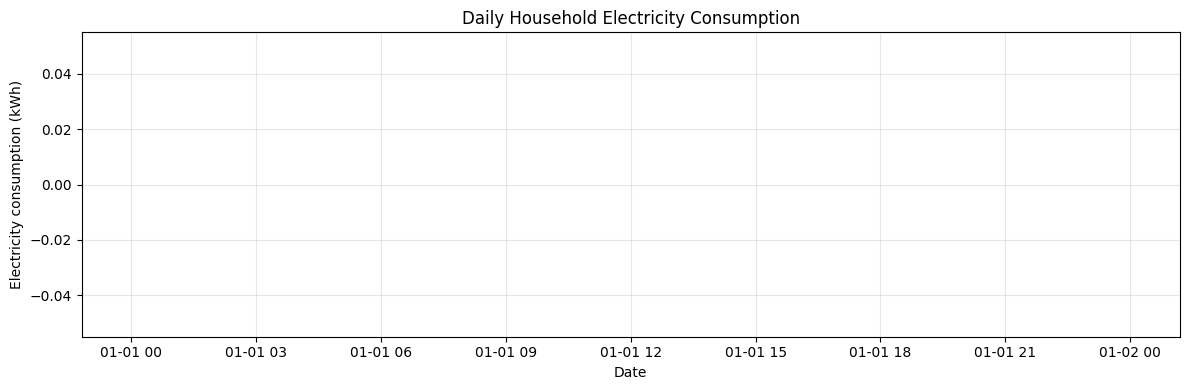

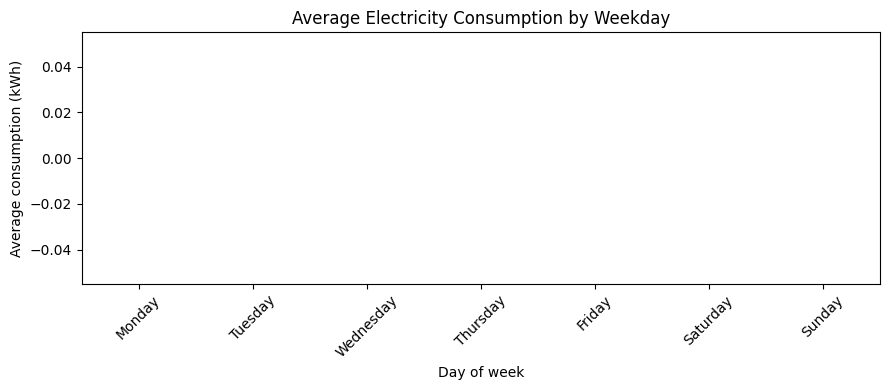

In [17]:

import matplotlib.pyplot as plt

# Plot daily electricity consumption
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily["daily_kwh"], linewidth=0.7)
plt.title("Daily Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Electricity consumption (kWh)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot average consumption by weekday
weekday_avg = daily.groupby(daily.index.day_name())["daily_kwh"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_avg = weekday_avg.reindex(weekday_order)

weekday_avg.plot(kind="bar", figsize=(9, 4))
plt.title("Average Electricity Consumption by Weekday")
plt.xlabel("Day of week")
plt.ylabel("Average consumption (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

all_days = pd.date_range(
    daily.index.min(),
    daily.index.max(),
    freq="D"
)

missing_days = all_days.difference(daily.index)

print("First date:", daily.index.min().date())
print("Last date:", daily.index.max().date())
print("Number of daily records:", len(daily))
print("Missing calendar days:", len(missing_days))

print("\nLowest daily consumption:")
display(daily.nsmallest(5, "daily_kwh"))

print("\nHighest daily consumption:")
display(daily.nlargest(5, "daily_kwh"))


First date: 2006-12-16
Last date: 2010-11-26
Number of daily records: 1433
Missing calendar days: 9

Lowest daily consumption:


,daily_kwh
datetime,
2009-06-13,0.236967
2007-04-28,0.378967
2010-08-22,1.555633
2010-09-25,1.766767
2010-03-20,2.195533



Highest daily consumption:


,daily_kwh
datetime,
2006-12-23,79.556433
2007-02-03,67.162033
2006-12-26,65.568500
2007-02-18,63.829367
2007-02-04,59.932333


In [ ]:

# Create a copy of the daily dataset
model_data = daily.copy()

# Add yesterday's electricity consumption
model_data["previous_day_kwh"] = (
    model_data["daily_kwh"].shift(1)
)

# Add calendar features
model_data["day_of_week"] = model_data.index.dayofweek
model_data["month"] = model_data.index.month

# Remove the first row because it has no previous-day value
model_data = model_data.dropna()

print("Feature engineering completed!")
print("Dataset shape:", model_data.shape)

print("\nFirst five rows:")
display(model_data.head())


Feature engineering completed!
Dataset shape: (1432, 4)

First five rows:


,daily_kwh,previous_day_kwh,day_of_week,month
datetime,,,,
2006-12-17,56.507667,20.152933,6,12
2006-12-18,36.730433,56.507667,0,12
2006-12-19,27.769900,36.730433,1,12
2006-12-20,37.095800,27.769900,2,12
2006-12-21,28.610400,37.095800,3,12


In [ ]:

# Select input features and prediction target
X = model_data[
    ["previous_day_kwh", "day_of_week", "month"]
]

y = model_data["daily_kwh"]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:", X_train.index.min().date(),
      "to", X_train.index.max().date())
print("Testing dates:", X_test.index.min().date(),
      "to", X_test.index.max().date())


Training rows: 1145
Testing rows: 287
Training dates: 2006-12-17 to 2010-02-06
Testing dates: 2010-02-07 to 2010-11-26


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd
import matplotlib.pyplot as plt

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict electricity consumption for test dates
y_pred = model.predict(X_test)

# Evaluate prediction accuracy using MAE
mae = mean_absolute_error(y_test, y_pred)

print("Model training completed!")
print("Mean Absolute Error (MAE):", round(mae, 3), "kWh")


Model training completed!
Mean Absolute Error (MAE): 4.956 kWh


First 10 actual vs predicted values:


,Actual_kWh,Predicted_kWh
datetime,,
2010-02-07,27.095133,40.724445
2010-02-08,43.037300,24.417865
2010-02-09,40.348867,34.869897
2010-02-10,32.409033,34.170820
2010-02-11,22.829467,30.328585
2010-02-12,31.549967,25.504909
2010-02-13,39.192600,31.634504
2010-02-14,28.111633,37.118956
2010-02-15,34.952200,25.026278


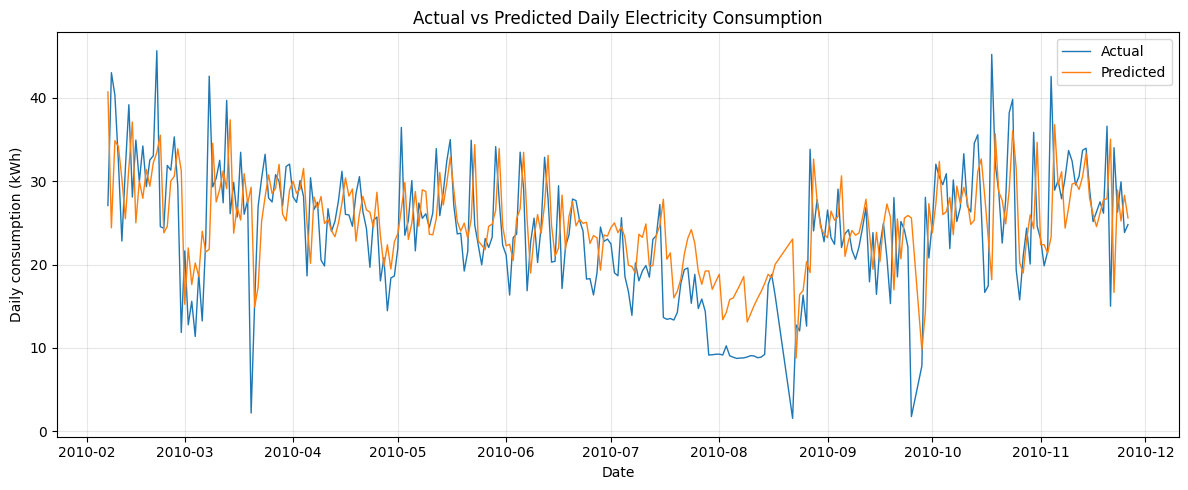

In [ ]:

results = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": y_pred
})

print("First 10 actual vs predicted values:")
display(results.head(10))

plt.figure(figsize=(12, 5))
plt.plot(results.index, results["Actual_kWh"],
         label="Actual", linewidth=1)
plt.plot(results.index, results["Predicted_kWh"],
         label="Predicted", linewidth=1)
plt.title("Actual vs Predicted Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Daily consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Example tariff: ₹8 per electricity unit (kWh)
# This is an assumption, not your verified local tariff.
tariff_per_kwh = 8.0

# Get the latest available date and consumption
last_day_kwh = daily["daily_kwh"].iloc[-1]
next_date = daily.index[-1] + pd.Timedelta(days=1)

# Prepare input features for the next day
next_features = pd.DataFrame({
    "previous_day_kwh": [last_day_kwh],
    "day_of_week": [next_date.dayofweek],
    "month": [next_date.month]
})

# Predict the next day's electricity consumption
predicted_kwh = model.predict(next_features)[0]
predicted_kwh = max(0, predicted_kwh)

# Estimate a 30-day cost using this daily prediction
estimated_monthly_kwh = predicted_kwh * 30
estimated_bill = estimated_monthly_kwh * tariff_per_kwh

print("Next prediction date:", next_date.date())
print("Predicted daily consumption:",
      round(predicted_kwh, 2), "kWh")
print("Estimated 30-day consumption:",
      round(estimated_monthly_kwh, 2), "kWh")
print("Assumed tariff: ₹", tariff_per_kwh, "per kWh")
print("Estimated 30-day energy cost: ₹",
      round(estimated_bill, 2))


Next prediction date: 2010-11-27
Predicted daily consumption: 27.08 kWh
Estimated 30-day consumption: 812.26 kWh
Assumed tariff: ₹ 8.0 per kWh
Estimated 30-day energy cost: ₹ 6498.1


In [ ]:

print("PROJECT: Electricity Bill Predictor")
print("-" * 40)
print("Model: Linear Regression")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Mean Absolute Error (MAE):",
      round(mae, 3), "kWh")
print("Latest historical daily usage:",
      round(float(daily["daily_kwh"].iloc[-1]), 2), "kWh")
print("Predicted next-day usage:",
      round(float(predicted_kwh), 2), "kWh")
print("Estimated 30-day energy cost: ₹",
      round(float(estimated_bill), 2))


PROJECT: Electricity Bill Predictor
----------------------------------------
Model: Linear Regression
Training records: 1145
Testing records: 287
Mean Absolute Error (MAE): 4.956 kWh
Latest historical daily usage: 24.8 kWh
Predicted next-day usage: 27.08 kWh
Estimated 30-day energy cost: ₹ 6498.1
